### Figure 4: Vulnerable branching ratio $\kappa$ for beta-binomial graphs

This code plots the vulnerable branching/cascade parameter $\kappa$ as a function of mean degree $z=\langle k \rangle$ at constant threshold $\phi = 0.25$ for verying skews of BB distribution and for ER, to illustrate the effect of degree heterogeneity on the shape of the contour.

In [2]:
# Import statements
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson, betabinom
from figstyle import PALETTE, LW, REF_LW, FIGW_SINGLE, save

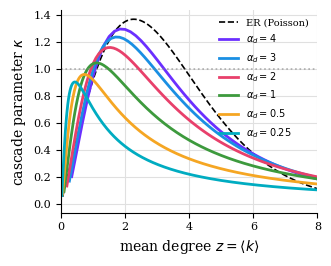

In [3]:
# Define  threshold, the ER kmax, the max n and fixed beta.
phi = 0.25
k_trig = int(1 / phi)
n_max = 5000
n_vals = np.arange(2, n_max + 1)
beta_bb = 20.0

# Sets of BB alphas to sweep over.
alpha_sets = [
    (4.,   r'$\alpha_d=4$'),
    (3.,   r'$\alpha_d=3$'),
    (2.,   r'$\alpha_d=2$'),
    (1.,   r'$\alpha_d=1$'),
    (0.5,  r'$\alpha_d=0.5$'),
    (0.25, r'$\alpha_d=0.25$'),
]

# Poisson reference curve
z_ref = np.linspace(0.05, 8, 800) # iterate over mean degree 
kappa_er = []

for z in z_ref:
    # compute kappa = sum_k^kmax k(k-1)p_k/z over iterated z
    pk = poisson.pmf(np.arange(k_trig + 1), z)
    pk[0] = 0.0
    ks = np.arange(k_trig + 1)
    kappa_er.append(np.sum(ks[2:] * (ks[2:] - 1) * pk[2:]) / z)

# Plot the Poisson curve
fig, ax = plt.subplots(figsize=(FIGW_SINGLE, 2.7))
ax.plot(z_ref, kappa_er, lw=REF_LW, color='black', ls='--', label='ER (Poisson)')

# Discretize k in up to n
ks = np.arange(n_max + 1)
results = {}

for i, (alpha_d, label) in enumerate(alpha_sets):
    # iterate through each (alpha, beta) pair
    kappas, means = [], []
    for n in n_vals:
        # for all (n,k) compute P(a,b,n,k)
        pk = betabinom.pmf(ks[:n + 1], n, alpha_d, beta_bb)

        # compute average degree sum_k k p_k
        mk = (ks[:len(pk)] * pk).sum()

        # compute k up to the always-vulnerable cutoff
        kmin = min(k_trig + 1, len(pk))

        # compute kappa = k (k-1) p_k/<k>
        w = ks[2:kmin] * (ks[2:kmin] - 1) * pk[2:kmin] / mk

        kappas.append(w.sum())
        means.append(mk)
        
    # Plot the kappa vs appropriately computed <k>
    results[alpha_d] = (np.array(means), np.array(kappas))
    ax.plot(means, kappas, lw=LW, color=PALETTE[i], label=label)


ax.axhline(1.0, color='gray', ls=':', lw=REF_LW, alpha=0.6)
ax.set_xlabel(r'mean degree $z=\langle k\rangle$')
ax.set_ylabel('cascade parameter $\\kappa$')
ax.set_xlim(0, 8)
ax.legend(loc='best', frameon=False, fontsize=7)
fig.tight_layout()
save(fig, "figure4")
plt.show()

Below, we run some numerical checks.

In [4]:
# We check behavior in the upper crossing of kappa=1 for more values than plotted.
def kappa_at(alpha_d, n):
    p2, p3, p4 = (betabinom.pmf(k, n, alpha_d, beta_bb) for k in (2, 3, 4))
    mean = n * alpha_d / (alpha_d + beta_bb)
    return (2 * p2 + 6 * p3 + 12 * p4) / mean

def upper_crossing(alpha_d):
    m_d = alpha_d / (alpha_d + beta_bb)
    n = np.arange(4, int(8 / m_d) + 2)
    z = n * m_d
    kappa_values = kappa_at(alpha_d, n)
    crossings = np.where(np.diff(np.sign(kappa_values - 1.0)) != 0)[0]
    if len(crossings) == 0:
        return 0.0
    i = crossings[-1]
    return z[i] + (1 - kappa_values[i]) * (z[i + 1] - z[i]) / (kappa_values[i + 1] - kappa_values[i])

alpha_d_dense = np.linspace(5.0, 0.01, 100)
upper = np.array([upper_crossing(alpha_d) for alpha_d in alpha_d_dense])

# We check that the window narrows monotonically as alpha_d decreases.
assert np.all(np.diff(upper) <= 1e-9), "window should narrow monotonically with alpha_d"
print(f"The window narrows monotonically for alpha_d on the interval [5, 0.01] with upper z = {upper[0]:.2f} going to z= {upper[-1]:.2f}.")

# We check that the window vanishes below some alpha_d and stays vanished.
assert upper[-1] == 0.0, "window should vanish for the smallest alpha_d"
vanished = np.where(upper == 0.0)[0][0]
print('The window vanishes for the samllest choice of alpha_d.')

assert np.all(upper[vanished:] == 0.0), "window should stay vanished below the threshold"
print(f"The window vanishes at an alpha_d <= {alpha_d_dense[vanished]:.3f}.")

The window narrows monotonically for alpha_d on the interval [5, 0.01] with upper z = 3.42 going to z= 0.00.
The window vanishes for the samllest choice of alpha_d.
The window vanishes at an alpha_d <= 0.665.
